<a href="https://colab.research.google.com/github/nacrocker/automated-segmentation/blob/max-burgers-branch/Maxs_AE_Isolator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title Machinery and Utilities

import numpy as np
from scipy.signal import chirp
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import Normalize
from sklearn.cluster import OPTICS
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.signal import ShortTimeFFT
import random as rng
import pandas as pd
import scipy.linalg
import scipy.sparse.linalg
import scipy.stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from scipy.signal import ShortTimeFFT
import os
from google.colab import drive




def blackman_vs_tau(tau):
    """Blackman window vs normalized time (0 <= tau <= 1)
       This gives numpy.blackman(M) == blackman_vs_tau(taus) for taus = (numpy.arange(1-M, M, 2)/(M-1)/2) + 0.5
    """
    return 0.42 + 0.5*np.cos(2*np.pi*(tau-0.5)) + 0.08* np.cos(4*np.pi*(tau-0.5)) #0 <= tau <= 1
#helps taper ft data at the ends where gibbs phenomena occurs

#def make_noise(mean, std, shape, noise_generator = np.random.normal):
def getSavedRndGenSeed():
    global SavedRndGenSeed
    if not 'SavedRndGenSeed' in globals():
        SavedRndGenSeed = np.random.SeedSequence()
    return SavedRndGenSeed
    #makes sure random number reproducibility is possible


def make_noise(mean=0.0, std=1.0, shape=None, noise_generator = None, seed = None):
    if noise_generator is None: noise_generator = np.random.default_rng(seed=seed).normal
    return noise_generator(mean, std, shape)
    #generates array of random numbers based on a mean, std, and shape
    #shape of output array is (n,)

import typing
class Chirp(typing.NamedTuple):
    amp: float = 1.0
    envlf: typing.Callable[...,typing.Any] = blackman_vs_tau
    t0: float = 0.0  #seconds
    t1: float = 1.0  #seconds
    f0: float = 1000.0 #Hz
    f1: float  = 11000.0 #Hz
    phi: float = 0.0 #degrees
    method: str = 'quadratic'
    vertex_zero: bool = True

    def __call__(self,t):
        """make chirp, c(t):
           t:  array-like float
           for t such that self.t0 <= t <= self.t1:
               c(t) = amp*envlf((t-self.t0)/(self.t1-self.t0))*
               scipy.signal.chirp(t-self.t0, self.f0, self.t1-self.t0, self.f1, method=self.method, phi=self.phi, vertex_zero=self.vertex_zero)
               where envlf is a continuous function that defines values for 0<= t <= 1.
                   the default, blackman_vs_tau, is inspired by the blackmann window where, for 0 <= t <= 1:
                   blackman_vs_tau(t) = 0.42 + 0.5*cos(2*np.pi*(t-0.5)) + 0.08*cos(4*np.pi*(t-0.5))
              self.method defaults to quadratic and self.vertex_zero defaults to true.
           for t such that t <=self.t0 or self.t1 <= t: c(t) = 0
        """
        import numpy as np
        from scipy.signal import chirp
        t = np.asarray(t).flatten()
        nt = t.size
        sig=np.zeros((nt,),dtype=float)
        it0 = np.searchsorted(t,self.t0)
        it1 = np.searchsorted(t,self.t1,side='right')-1
        ntch=it1-it0+1
        if ntch > 0:
            envl=self.envlf((t[it0:it0+ntch]-self.t0)/(self.t1-self.t0))
            sig[it0:it0+ntch] = self.amp*envl*chirp(t[it0:it0+ntch]-self.t0, self.f0, self.t1-self.t0, self.f1, method=self.method, phi=self.phi, vertex_zero=self.vertex_zero)
        return sig
        #allows one to treat chirp objects as functions

def add_funcsigs(sigfunclist,t):
    sig = 0.0
    for sgf in sigfunclist: sig+=sgf(t)
    return sig
    #sums multiple signals together


## end synthetic signal machinery

## begin max_tree_machinery

class Cached_Computed_Attributes:
    '''mixin class with methods for managing cached computed attributes'''

    @staticmethod
    def cached_computed_attribute(attribute_name):
        def cached_computer_attribute_decorator(attribute_compute_method):

            def attribute_compute_method_with_caching(self):
                if self.is_cached(attribute_name):
                    ret = self.get_cached(attribute_name)
                    if not (ret is None): return ret

                attribute = attribute_compute_method(self)

                self.cache(attribute_name,attribute)
                return attribute

            return property(attribute_compute_method_with_caching)
        return cached_computer_attribute_decorator


    _listy_types = (list, tuple)
    def cache(self,attr,val):
        """Cache a computed attribute"""
        if (attr,str):
            setattr(self,'_'+attr,val)
            self._cached[attr]=attr
            return None

    @property
    def cached(self):
        """Get dictionary of cached computed attributes."""
        return {k:getattr(self,'_'+k) for k in self._cached.keys()}

    def list_cached(self):
        """Get names of cached computed attributes."""
        return self._cached.keys()

    def is_cached(self,attr):
        """Test if attribute or list of attribures is cached"""
        if isinstance(attr,self.__class__._listy_types):
            return [self.is_cached(a) for a in attr]

        if isinstance(attr,str):
            return attr in self._cached and hasattr(self,'_'+attr)

        #if this point is reached, something is wr

    def add_alias_to_cached(self,attr,alias):
        """Add alias or list of alias to attributes"""

        if isinstance(attr,self.__class__._listy_types) and isinstance(alias,self.__class__._listy_types) and len(attr) == len(alias):
            for a,al in zip(attr,alias): self.add_alias_to_cached(a,al)
            return None

        if isinstance(attr,str):
            if self.is_cached(attr) is None: raise KeyError(attr)
            self._cached[alias] = attr
            return None

        #if this point is reached, something is wrong.
        raise ValueError('attr should be attribute name or list of attribute names.')


    def is_alias_to_cached(self,attr):
        """Test if atrributes are aliass to other attributes."""
        if isinstance(attr,_listy_types):
            return [self.is_alias_to_cached(a) for a in attr]

        if isinstance(attr,str):
            if self.is_cached(attr) is None: raise KeyError(attr)
            return attr == self._cached[attr]

        #if this point is reached, something is wrong.
        raise ValueError('attr should be attribute be name or list of attribute names.')


    def dereference_alias(self,attr):
        """Dereference aliases to cached computed attributes. Non-aliases will deference to themselves."""
        if isinstance(attr,self.__class__._listy_types):
            return [self.dereference_alias(a) for a in attr]

        if isinstance(attr,str):
            if self.is_cached(attr) is None: raise KeyError(attr)
            return self._cached[attr]

        #if this point is reached, something is wrong.
        raise ValueError('attr should attribute name or list of attribute names.')


    def get_cached(self,attr):
        """Get cached computed attribute values"""
        if isinstance(attr,self.__class__._listy_types):
            return [self.get_cached(a) for a in attr]

        if isinstance(attr,str):
            if self.is_cached(attr) is None: raise KeyError(attr)
            return getattr(self,'_'+attr)

        #if this point is reached, something is wrong.
        raise ValueError('attr should be attribute name or list of attribute names.')


    def clear_cached(self,attr=None,all=False):
        """Clear cached computed attributes by name or list of names, or all by all=True."""
        def _safe_clear_cached(attr):
            if hasattr(self,'_'+attr): delattr(self,'_'+attr)
            if attr in self._cached: self._cached.pop(attr)

        if attr is None: return None

        if all:
            for a in attr: self.clear_cached(a)
            return None

        if isinstance(attr,self.__class__._listy_types):
            for a in attr: self.clear_cached(a)
            return None

        if isinstance(attr,str):
            if self.is_cached(attr) is None: raise KeyError(attr)
            _safe_clear_cached(attrs)
            return None

        #if this point is reached, something is wrong.
        raise ValueError('attr should be attribute name or list of attribute names, or all=True should be provided.')


class Max_Tree(Cached_Computed_Attributes):
    import numpy as np

    def __init__(self,image=None,connectivity=1):
        self._cached={}
        self._connectivity = connectivity
        if image is None:
            self._image=None
            self._connectivity=None
            self._P=None
            self._S=None
            return
        from skimage.morphology import max_tree as max_tree_ski
        self._image = image
        self._P,self._S = max_tree_ski(image, connectivity=self._connectivity)


    @property
    def image(self):
        """Get the max_tree image"""
        return self._image

    @property
    def intensity(self):
        """Get the max_tree image""" #check this later
        return self._image

    @property
    def P(self):
        """Get the max_tree parent matrix"""
        return self._P

    @property
    def S(self):
        """Get the max_tree traverser array"""
        return self._S

    @property
    def parent(self):
        """Get max_tree parent matrix"""
        return self.P

    @property
    def sorted_indices(self):
        """Get max_tree sorted_indices array"""
        return self.S

    @property
    def connectivity(self):
        """Get the max_tree connectivity."""
        return self._connectivity

    cached_computed_attribute=Cached_Computed_Attributes.cached_computed_attribute

    @cached_computed_attribute('C')
    def C(self):
        S = self.S
        P_rav = self.P.ravel()
        C_rav = [[] for _ in range(len(P_rav))]
        C = np.empty(self.image.shape,dtype=list)
        for p in S[1:]:
            q = P_rav[p]
            C_rav[q].append(p)
        C.ravel()[:]= C_rav[:]
        return C

    @cached_computed_attribute('children')
    def children(self):
        return self.C

    @cached_computed_attribute('canonicality')
    def canonicality(self):
        """Get the canonicality of each position in P, the parent matrix. i.e. whether it represents a component"""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        canonicality_rav = image_rav != image_rav[parent]
        p_root = sorted_indices[0]
        canonicality_rav[p_root] = True
        canonicality = np.reshape(canonicality_rav,self.P.shape)

        return canonicality

    @cached_computed_attribute('numcomponents')
    def numcomponents(self):
        """Get the number of components."""
        if self._image is None: return None

        numcomponents = np.sum(self.canonicality)
        return numcomponents


    @cached_computed_attribute('sorted_labels')
    def sorted_labels(self):
        """Get the component labels for each of the node in S, the sorted_indices array.
        Non-canonical nodes have a value equal to the negative of their canonical parent label.
        Label magnitudes increase from 0 starting at beginning of sorted_labels. """
        if self._image is None: return None

        sorted_labels=np.cumsum(self.canonicality[self.S])
        sorted_labels[~self.canonicality[self.S]] *= -1
        return sorted_labels

    @cached_computed_attribute('labels')
    def labels(self):
        """Get the component labels for each of the node in P, the parent matrix.
        Non-canonical nodes have a value equal to the negative of their canonical parent label."""
        if self._image is None: return None

        labels = self._P.copy()
        labels.ravel()[self.S] = self.sorted_labels

    @cached_computed_attribute('component_P_indices')
    def component_P_indices(self):
        """Get the indices (aka P-indices) in P, or the parent matrix, for the node correposonding to component to which the node belongs.
        For a canonical node, component_P_indices.ravel()[i] == i."""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        indices=np.reshape(np.arange(parent.size),self.P.shape)
        indices_rav=indices.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            if image_rav[q] == image_rav[p]: indices_rav[p]=indices_rav[q]

        return indices

    @cached_computed_attribute('order')
    def order(self):
        """Get the position within S, the sorted_indices array, of nodes in P, the parent matrix.
        In other words, for a node i in P.ravel(), S[order[i]] == i"""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        order = np.argsort(self.sorted_indices)

        return order

    @cached_computed_attribute('order_P_indices')
    def order_P_indices(self):
        """Get the order within S, the sorted_indices array, of the P-indices (component indices in P).
        For a canonical node i in P.ravel(), S[order_P_indices[i]] == i.
        For a non-canoncical node i in P.ravel(), S[order_P_indices[i]] == P.ravel[i]"""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        order = self.order

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            if image_rav[q] == image_rav[p]:
                order[p] = order[q]

        return order


    @cached_computed_attribute('numchildren')
    def numchildcomponents(self):
        """Get the number of child components for each comoenent node.
        Non-canonical nodes will have values which are the negative of the number of components for their parent component node."""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        numchildren = np.zeros(image.shape, dtype=int)
        numchildren_rav=numchildren.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            if image_rav[q] != image_rav[p]:
                numchildren_rav[q] += 1

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            if image_rav[q] == image_rav[p]:
                numchildren_rav[p] = -numchildren_rav[q]

        return numchildren

    @cached_computed_attribute('numchildnodes')
    def numchildnodes(self):
        """Get the number of children in the max-tree for each tree node (count includes non-canonical nodes)."""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        numchildren = np.zeros(image.shape, dtype=int)
        numchildren_rav=numchildren.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            numchildren_rav[q] += 1

        return numchildren

    @cached_computed_attribute('leaf_P_indices')
    def leaf_P_indices(self):
        """Get the P-indices of component leaf nodes. (Note that non-canonical nodes are leaf nodes but not component leave nodes.)"""
        if self._image is None: return None

        return np.flatnonzero(self.numchildnodes == 0)

    @property
    def leaves(self):
        """Alias for leaf_P_indices"""
        return self.leaf_P_indices

    @cached_computed_attribute('sorted_leaf_P_indices')
    def sorted_leaf_P_indices(self):
        """Get the P-indices ??? of component leaf nodes. (Note that non-canonical nodes are leaf nodes but not component leaf nodes.)"""
        if self._image is None: return None

        return self.S[np.flatnonzero(self.numchildnodes.ravel()[self.S] == 0)]

    @cached_computed_attribute('peak')
    def peak(self):
        """Get the peak (max intensity) for each component."""
        if self._image is None: return None

        image = self._image
        parent = self._P.ravel()
        sorted_indices = self._S

        peak = image.copy()

        image_rav = image.ravel()
        peak_rav = peak.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            if image_rav[p] != image_rav[q]:
                peak_rav[q] = max(peak_rav[p], peak_rav[q])  # search maximum and propagate maximum to parent node
            else:
                # canonicalize value. this works because the sort_indices order will cause all
                # canonical children of q to be reached before non-canonical children
                peak_rav[p] = peak_rav[q]
        return peak



    @property
    def contrast(self):
        """Get the contrast for each component. contrast=max_over_component(intensity)/min_over_component(intensity)"""
        if self._image is None: return None

        contrast = ((self.peak).copy()).astype(np.float64)/self._image

        return contrast


    @property
    def log_contrast(self):
        """Get the log of contrast for each component. logContrast = log(max_over_component(intensity)) - log(min_over_component(intensity))."""
        if self._image is None: return None

        log_contrast = np.log(((self.peak).copy()).astype(np.float64))-np.log(self._image)

        return log_contrast


    @cached_computed_attribute('height')
    def height(self):
        """Get the height for each component.  Height = max_over_component(intensity)-min_over_component(intensity)"""
        if self._image is None: return None

        height = ((self.peak).copy()).astype(np.float64)-self._image

        return height

    @cached_computed_attribute('area')
    def area(self):
        """Get the area (number of pixels) for each component."""
        if self._image is None: return None

        image = self._image #creates freq/time spectrogram
        image_rav = image.ravel() #make image an array
        parent = self._P.ravel() #get the parent indices of each pixel
        sorted_indices = self._S #each pixel is preceeded by its parent, so the leaves are at the end

        area = np.ones(image.shape, dtype=int) #initialize grid of ones
        area_rav=area.ravel() #turn into array

        for p in sorted_indices[:0:-1]: #go through sorted indices (p) back wards, so top of tree first
            q = parent[p] #q is then the parent of p
            area_rav[q] += area_rav[p] #area of the parent pixel = it's area plus the area of it's leaf

        for p in sorted_indices[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]: #if a pixel and it's parent are the same
                area_rav[p] = area_rav[q] # canonicalize value

        return area



    @cached_computed_attribute('volume')
    def volume(self):
        """Get the volume for each component. Volume = sum_over_component(intensity-min_over_parent_component(intensity))"""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S
        area = self.area
        area_rav=area.ravel()

        volume = np.zeros(image.shape, dtype=np.float64)
        volume_rav=volume.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            if image_rav[p] != image_rav[q]:
                volume_rav[q] += area_rav[p]*(image_rav[p]-image_rav[q])+volume_rav[p]

        for p in sorted_indices[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]:
                volume_rav[p] = volume_rav[q] # canonicalize value

        return volume


    @cached_computed_attribute('r_squared')
    def r_squared(self):
        """Get r_squared for each component"""
        if self._image is None: return None

        image = self._image #original image
        image_rav = image.ravel() #ravelled image
        parent = self._P.ravel() #ravelled matrix where each value is the index of it's parent in ravelled array
        sorted_indices = self._S #array where pixels are ordered such that each pixel is preceeded by it's parents and each value is the ravelled image index

        volume = np.zeros(image.shape, dtype=np.float64)
        volume_rav=volume.ravel()

        for p in sorted_indices[:0:-1]: # traverse through ordered mt components from leave to root
            q = parent[p] #index of the parent of the pixel p
            if image_rav[p] != image_rav[q]: #if pixel p's gain not equal to parent's gain
                volume_rav[q] += area_rav[p]*(image_rav[p]-image_rav[q])+volume_rav[p]

        for p in sorted_indices[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]:
                volume_rav[p] = volume_rav[q] # canonicalize value

        return volume



    @cached_computed_attribute('total_image')
    def total_image(self):
        """Get the total_image (sum of image values) for each component."""
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        total_image = np.copy(image)
        total_image_rav=total_image.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            total_image_rav[q] += total_image_rav[p]

        for p in sorted_indices[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]:
                total_image_rav[p] = total_image_rav[q] # canonicalize value

        return total_image

    @property
    def total_intensity(self):
        """Get the total_intensity (sum of intensities) for each component."""
        return self.total_image

    @cached_computed_attribute('intensity_entropy')
    def image_entropy(self):
        """Get the entropy for each component, -sum(total_image_fraction*log(total_image_fraction)), where total_image_fraction = (image value)/total_image """
        if self._image is None: return None

        image = self._image
        image_rav = image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        image_entropy = -image*np.where(image > 0,np.log(image),0)
        image_entropy_rav=image_entropy.ravel()

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            image_entropy_rav[q] += image_entropy_rav[p]

        for p in sorted_indices[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]:
                image_entropy_rav[p] = image_entropy_rav[q] # canonicalize value

        image_entropy = (lambda a,n: a/n + np.log(n))(image_entropy,self.total_image)
        return image_entropy

    @property
    def intensity_entropy(self):
        """Get the entropy for each component, -sum(total_intensity_fraction*log(total_intensity_fraction)), where total_intensity_fraction = intensity/total_intensity """
        return self.image_entropy

    @cached_computed_attribute('extents')
    def extents(self):
        """Get the extent (index ranges for each coordinate) for each component."""
        if self._image is None: return None

        image = self._image
        image_rav=image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S

        number_of_pixels = np.size(image)

        max_coord = np.array(np.unravel_index(np.arange(number_of_pixels), image.shape)).T
        min_coord = np.array(np.unravel_index(np.arange(number_of_pixels), image.shape)).T
        extents = np.ones((*image.shape,2),dtype=int)
        extents_rav = extents.reshape((number_of_pixels,2))

        for p in sorted_indices[:0:-1]:
            q = parent[p]
            max_coord[q] = np.maximum(max_coord[q], max_coord[p])
            min_coord[q] = np.minimum(min_coord[q], min_coord[p])
            extents_rav[q] = (max_coord[q] - min_coord[q]) + 1

        for p in sorted_indices[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]:
                extents_rav[p] = extents_rav[q] # canonicalize value

        return extents

    @property
    def extension(self):
        """Get the maximum of all extents (index ranges for each coordinate) for each component."""
        if self._image is None: return None

        return np.max(self.extents,axis=2)

    @property
    def diameter(self):
        """Get diameter (alias for extension) for each component."""
        return self.extension


    def fill_components_from_markers(self,markers=None,unmarked=0,preserve_nesting=False):

        image = self._image
        if markers is None or not np.array_equal(markers.shape,image.shape):
            raise ValueError('markers should be matrix with same shape as image')

        image=self.image
        image_rav=image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S
        output = markers.copy()
        output_rav=output.ravel()

        if np.isnan(unmarked):
            for p in sorted_indices[:0:-1]:
                #if noncanonical node is marked, mark canonical parent
                q = parent[p]
                if image_rav[q] == imag_rav[p] and ~np.isnan(output_rav[p]): output_rav[q] = output_rav[p]

            for p in sorted_indices[1:]:
                q = parent[p]
                if ~np.isnan(output_rav[q]) and (not preserve_nesting or np.isnan(output_rav[p])) : output_rav[p] = output_rav[q]
        else:
            for p in sorted_indices[:0:-1]:
                #if noncanonical node is marked, mark canonical parent
                q = parent[p]
                if image_rav[q] == image_rav[p] and output_rav[p] != unmarked: output_rav[q] = output_rav[p]

            for p in sorted_indices[1:]:
                # is parent is marked, mark child.
                q = parent[p]
                if output_rav[q] != unmarked and (not preserve_nesting or output_rav[p] == unmarked): output_rav[p] = output_rav[q]

        return output


    def direct_filter(self,attribute='area',attribute_threshold=3):
        """Apply a direct filtering.

        This produces an image in which for all possible thresholds, each connected
        component has the specified attribute value greater than that threshold.
        This is the basic function called by :func:`area_opening`,
        :func:`diameter_opening`, and similar.

        For :func:`area_opening`, for instance, the attribute is the area.  In this
        case, an image is produced for which all connected components for all
        thresholads have at least an area (pixel count) of the threshold given by
        the user.

        Parameters
        ----------

        attribute : name of attribute or array of float with same shape as image
            that ontains the attributes computed for the max-tree.
        attribute_threshold : float
            The threshold to be applied to the attribute.

        Notes
        ----------
        Adapted from source code for skimage max_tree:
        https://github.com/scikit-image/scikit-image/blob/v0.25.2/skimage/morphology/_max_tree.pyx
        """

        image = self._image

        isvalidattr = False
        if isinstance(attribute,str) and hasattr(self,attribute):
                attrtemp=getattr(self,attribute)
                if np.array_equal(attrtemp.shape,image.shape):
                    attribute=attrtemp
                    isvalidattr = True
        else:
            if np.array_equal(attribute.shape,image.shape): isvalidattr = True

        if not isvalidattr:  raise ValueError('attr should be attribute name or array with same shape as image')


        image_rav=image.ravel()
        parent = self._P.ravel()
        sorted_indices = self._S
        attribute_rav=attribute.ravel()

        output = image.copy()
        output_rav=output.reshape((size(image),*output.shape[2:]))

        p_root = sorted_indices[0]
        if attribute_rav[p_root] < attribute_threshold:
            output_rav[p_root] = 0
        else:
            output_rav[p_root] = image_rav[p_root]

        for p in sorted_indices[1:]:
            q = parent[p]

            # this means p is not canonical
            # in other words, it has a parent that has the
            # same image value.
            if image_rav[p] == image_rav[q]:
                output_rav[p] = output_rav[q]
                continue

            if attribute_rav[p] < attribute_threshold:
                # this corresponds to stopping
                # as the level of the lower parent
                # is propagated to the current level
                output_rav[p] = output_rav[q]
            else:
                # here the image reconstruction continues.
                # The level is maintained (original value).
                output_rav[p] = image_rav[p]

        return output

    def maxattrclosing(self,attr,return_nodes=False):
        """propagates maxiumum attr value along lineage from root back to leaf. For non-monotonic attributes, this fills any valley between highest value descendenent and leaf"""
        image_rav = self.image.ravel()
        S=self.S
        parent=self.P.ravel()
        maxattr = attr.copy()
        maxattr_rav=maxattr.ravel()
        if return_nodes:
            maxattrnodes = np.zeros(attr.shape,dtype=bool)
            maxattrnodes_rav = maxattrnodes.ravel()
            maxattrnodes_rav[S[0]] = True
            for p in S[1:]:
                q=parent[p]
                if image_rav[p] != image_rav[q]:
                    if maxattr_rav[p] >= maxattr_rav[q]:
                        #maxattr_rav[p] = maxattr_rav[p]
                        maxattrnodes_rav[p] = True
                        maxattrnodes_rav[q] = False
                    else:
                        maxattr_rav[p] = maxattr_rav[q]
                else:
                    maxattr_rav[p] = maxattr_rav[q] #canoicalize maxattr
            return (maxattr,maxattrnodes)
        else:
            for p in S[1:]:
                q=parent[p]
                if image_rav[p] != image_rav[q]:
                    maxattr_rav[p] = np.maximum(maxattr_rav[p],maxattr_rav[q])
                else:
                    maxattr_rav[p] = maxattr_rav[q] #canoicalize maxattr
            return maxattr

    def leafattrflatnodes(self,attr,attrthresh=None,mask=None):
        """marks nodes for components with flat attribute value around leaves (e.g. from area opening) """
        image_rav=self.image.ravel()
        S=self.S
        parent=self.P.ravel()
        flatnodes = self.numchildnodes == 0 # will only mark true leaves, not non-canonical nodes.
        if not attrthresh is None: flatnodes = flatnodes & (attr >= attrthresh)
        if not mask is None: flatnodes = flatnodes & mask
        flatnodes_rav = flatnodes.ravel()
        attr_rav=attr.ravel()
        for p in S[:0:-1]:
            q=parent[p]
            if flatnodes_rav[p] and attr_rav[q] == attr_rav[p]:
                #move flatzone node marker to parent of flatzone
                flatnodes_rav[q] = True
                flatnodes_rav[p] = False
        return flatnodes

    def leafattrflatzones(self,attr,attrthresh=None,mask=None):
        """marks zones of flat attribute value around leaves (e.g. from area opening) """
        image_rav=self.image.ravel()
        S=self.S
        parent=self.P.ravel()
        flatzones=self.numchildnodes == 0  # mark leaves
        if not attrthresh is None: flatzones = flatzones & (attr >= attrthresh)  #mark leaves with attr above threshold
        if not mask is None: flatzones = flatzones & mask  # filter markers with mask
        flatzones_rav=flatzones.ravel()
        attr_rav=attr.ravel()
        for p in S[:0:-1]:
            q=parent[p]
            if flatzones_rav[p] and attr_rav[q] == attr_rav[p]: # non-canonical node should never satify flatzones_rav[p] == True here
                flatzones_rav[q] = True # propate marker to parent with same value of attr (i.e. parent in flatzone of child)
            #if flatzones_rav[q] and image_rav[p] == image_rav[q]:
            ## noncanonical node takes on flatzone membership if canonical parent it is in flatzone.
            ## parent should already have membership established because of order of S
            #    flatzones_rav[p] = True
        for p in S[1:]:
            q = parent[p]
            if image_rav[p] == image_rav[q]:
                flatzones_rav[p] = flatzones_rav[q] # canonicalize value


        return flatzones

    def path_to_root_as_P_indices(self,P_index):
        """Get path from node to root as P-indices"""
        if self._image is None: return None
        P_rav=self.P.ravel()
        def pathfrom(q):
            p = None
            while q != p:
                yield q
                p = q
                q = P_rav[p]

        return np.fromiter(pathfrom(P_index),int)

    def isdescendent(self,node=None,of=None):
        "Tests if node is descendent of another node. If nodes are non-canonical, their canonical parents are tested."
        if self._image is None: return None

        numP=self.P.size
        if not np.issubdtype(type(node),np.integer) or not node in range(numP):
             raise ValueError(f'"node" argument should be P-index , an integer in range({numP}).')
        if not np.issubdtype(type(of),np.integer) or not of in range(numP):
             raise ValueError(f'"of" argument should be P-index label, an integer in range({numP}).')


        P_rav=self.P.ravel()
        image_rav=self.image.ravel()
        S = self.S

        qof = P_rav[of]
        if of != S[0] and image_rav[of] == image_rav[qof]: of = qof

        if of == S[0]: return node != S[0]

        qnode = P_rav[node]
        if node != S[0] and image_rav[node] == image_rav[qnode]: node = qnode


        order = self.order.ravel()

        oforder=order[of]
        ancestor = node
        oldancestor = None
        while order[ancestor] >= oforder:
            oldancestor = ancestor
            ancestor = P_rav[oldancestor]

        return order[ancestor] == oforder


    def markancestors(self,nodes):
        image_rav=self.image.ravel()
        P_rav=self.P.ravel()
        ancestors=np.zeros(self.image.shape,dtype=bool)
        ancestors_rav=ancestors.ravel()

        for n in nodes:
            qn = P_rav[n]
            if image_rav[qn] == image_rav[n]: qn = P_rav[qn]
            while not ancestors_rav[qn] and qn != n:
                ancestors_rav[qn] = True
                n = qn
                qn = P_rav[n]
        return ancestors


    def maxattrnodes(self,attr,allchildren=True):
        """Find nodes which are local maxima of attr value along lineage. A maximum passes two tests:
        (1) attr.ravel()[parent] < attr.ravel()[node]
        (2) if allchildren:
              attr.ravel()[node] >= attr.ravel[child] for all children.
            else:
              attr.ravel()[node] >= attr.ravel[child] for any child.
        """
        S=self.S
        P_rav=self.P.ravel()
        image_rav=self.image.ravel()
        attr = attr.copy()

        attr_rav=attr.ravel()
        isnoncanonical = image_rav == image_rav[P_rav]
        attr_rav[isnoncanonical] = attr_rav[P_rav[isnoncanonical]] # canonicalize attr

        maxattrnodes=np.zeros(self.image.shape,dtype=bool)
        maxattrnodes_rav = maxattrnodes.ravel()

        ##Vectorized, faster code than for-loops below:
        maxattrnodes_rav[:] = (attr_rav[P_rav] <= attr_rav) & ~isnoncanonical
        if allchildren:
            np.logical_and.at(maxattrnodes_rav,P_rav,attr_rav[P_rav]>attr_rav)
        else:
            np.logical_or.at(maxattrnodes_rav,P_rav,attr_rav[P_rav]>attr_rav)

        return maxattrnodes

        ##Equivalent to, but slower than, vecotrized code above:
        #for p in S[1:]:
        #    q = P_rav[p]
        #    maxattrnodes_rav[p] = attr_rav[q] < attr_rav[p]
        #
        #if allchildren:
        #    for p in S[1:]:
        #        q = P_rav[p]
        #        maxattrnodes_rav[q] = maxattrnodes_rav[q] and attr_rav[q] >= attr_rav[p]
        #else:
        #    for p in S[1:]:
        #        q = P_rav[p]
        #        maxattrnodes_rav[q] = maxattrnodes_rav[q] or attr_rav[q] >= attr_rav[p]
        #return maxattrnodes


    def priorityprunenodes(self,nodeinds):
        """Given a list of nodes (by P-index) in order of increasing priorty, nodes with higher priority ancestors or decendents will be pruned."""
        from collections import deque

        image_rav=self.image.ravel()
        P_rav=self.P.ravel()
        nodes = np.zeros(self.P.shape,dtype=bool)
        nodes_rav = nodes.ravel()
        nodes_rav[nodeinds] = True
        children = self.children
        children_rav=children.ravel()
        occluded_rav=np.zeros(P_rav.shape,dtype=bool)

        for p in nodeinds[::-1]:
            q = P_rav[p]
            if image_rav[q] == image_rav[p]: # only deal with canonical nodes. no effect if node is actually root.
                p,q = q,P_rav[p]
            if occluded_rav[p]: continue # this maximum was eliminated in previous iteration
            pmax = p
            while not occluded_rav[q] and q != p:
                occluded_rav[q] = True
                p = q
                q = P_rav[p]

            #childqueue=children_rav[p][:]
            childqueue=deque(children_rav[pmax])
            while childqueue:
                c = childqueue.popleft()
                occluded_rav[c] = True
                childqueue.extend(children_rav[c])

        nodes_rav[:]&=~occluded_rav

        return np.flatnonzero(nodes_rav)


    def optimummaxattrnodes(self,attr,maxattrnodes=None):
        """Given a boolean matrix (maxattrnodes) where nodes with maximum attribute value are True, eliminate suboptimum maxima,
        which have any of these properties:
        1) a descendent maximum with higher or equal value
        2) an ancestor maximum with higher value that has no descendent maximum with even higher value
        If maxattrnodes argument is None, then calculate it."""

        from collections import deque

        image_rav=self.image.ravel()
        P_rav=self.P.ravel()
        if maxattrnodes is None:
            maxattrnodes = self.maxattrnodes(attr)
        else:
            maxattrnodes = maxattrnodes.copy()
        attr_rav=attr.ravel()
        maxattrnodes_rav = maxattrnodes.ravel()
        maxattrndinds = np.flatnonzero(maxattrnodes_rav)
        maxattrndinds = maxattrndinds[np.argsort(attr_rav[maxattrndinds])]
        children = self.children
        children_rav=children.ravel()
        occluded_rav=np.zeros(P_rav.shape,dtype=bool)

        for p in maxattrndinds[::-1]:
            q = P_rav[p]
            if image_rav[q] == image_rav[p]: # only deal with canonical nodes. no effect if node is actually root.
                p,q = q,P_rav[p]
            if occluded_rav[p]: continue # this maximum was eliminated in previous iteration
            pmax = p
            while not occluded_rav[q] and q != p:
                occluded_rav[q] = True
                p = q
                q = P_rav[p]

            #childqueue=children_rav[p][:]
            childqueue=deque(children_rav[pmax])
            while childqueue:
                c = childqueue.popleft()
                occluded_rav[c] = True
                childqueue.extend(children_rav[c])

        maxattrnodes_rav[:]&=~occluded_rav

        return maxattrnodes


    def accumulate_attribute_from_leaf_to_root(self,attr):
        """get the accumulated value of attr when walking tree from leaft to root. gives area if attr == np.ones(self.image.shape)"""
        image = self.image
        image_rav=image.ravel()
        P_rav = self.P.ravel()
        S = self.S
        acc=attr.copy()
        acc_rav = acc.reshape((np.size(image),*acc.shape[2:]))  # this is like ".ravel()" but designed to allow non-scalar attributes, like "extents", which a 2-element vector of vertical and horizontal extent for each node.

        for p in S[:0:-1]:
            q = P_rav[p]
            acc_rav[q]+=acc_rav[p]

        for p in S[1:]:
            q = P_rav[p]
            if image_rav[p] == image_rav[q]:
                acc_rav[p] = acc_rav[q] # canonicalize value

        return acc

    def label_image_components(self,nodeinds,labels,returnLabledNodes=False):
        labled_nodes = np.zeros(self.image.shape)
        np.put(labled_nodes,nodeinds,labels)
        labled = self.fill_components_from_markers(labled_nodes)
        if returnLabledNodes:
            return labled,labled_nodes
        else:
            return labled

    def label_optimummaxattrnode_image_components_with_rank_and_attr(self,attr):
        mxatnds = self.maxattrnodes(attr) # Find nodes which are local maxima of attr value along lineage.
        mxatnds = self.optimummaxattrnodes(attr,maxattrnodes=mxatnds) #prune attr-maximum nodes to leave only nodes with no descencdent having higher attr value. has shape of attr, with nonzero values for only surviving nodes
        mxatndinds = np.flatnonzero(mxatnds) # nonzero nodes mxatnds are the winners of the pruning. get their indices.
        mxatndinds = mxatndinds[np.argsort(attr.ravel()[mxatndinds])] # sort the indices in order for increasing attr value.
        mxatndsranktopfill, mxatndsranktop = self.label_image_components(mxatndinds,range(mxatndinds.size,0,-1),returnLabledNodes=True) #for each winning node, assiat integer rank label to node in matrix, with 1 as highest rank and higher integer for lower rank.  Fill components corresponding to nodes and return filled matrix along with matrix of ranked nodes.
        mxattop=attr*(mxatndsranktop > 0) # replace rank in ranked node matrix with attr value for node
        mxattopfill = self.fill_components_from_markers(mxattop) # fill components corresponding to nodes with their attr values.
        return mxatndsranktopfill,mxattopfill

    def gain_predefined(self,choice):
        predefined_gains = {
            'exp(entropy/area)': lambda: np.exp(self.intensity_entropy)*(self.extents[...,1]**2)*self.volume/(self.area**2),
            '1' : lambda: self.total_intensity*self.volume*self.extents[...,1]/(self.area**2),
            'skinny': lambda: np.exp(self.volume/self.area*self.extents[...,1]),
            'avspecdens': lambda: self.volume/self.area*self.extents[...,1],
            'avspecdens_div_freq': lambda : self.volume*self.extents[...,1]/(self.area*self.extents[...,0]),
            'avspecheight': lambda: self.volume/self.area,
            'kldiv_wresp_uniform_intensity': lambda: np.log(self.area)-self.intensity_entropy,
            'neg_kldiv_wresp_uniform_intensity': lambda: self.intensity_entropy-np.log(self.area),
            'log_energy_concentration': lambda: -self.intensity_entropy+np.where(self.total_intensity,np.log(self.total_intensity),0), # entropy = log(num_deg_freedom).  using intensity as energy, log(Energy/num_deg_freedom) = log(total_intensity/exp(entropy))
            'energy_concentration': lambda: self.total_intensity/np.exp(self.intensity_entropy), # entropy = log(num_deg_freedom).  using intensity as energy, Energy/num_deg_freedom = total_intensity/exp(entropy)
            'signal_energy_concentration': lambda: self.volume/np.exp(self.intensity_entropy), # entropy = log(num_deg_freedom).  using height (= intensity-threshold) as signal_energy, signal_energy/num_deg_freedom = volume/exp(entropy)
            'combo_specdens_signal_energy_concentration': lambda: (self.volume/self.area*self.extents [...,1] + self.volume/np.exp(self.intensity_entropy))/2,
            #the following don't work well at all
            #'signaltonoise': lambda: self.volume/(self.area*self.image),
            #'specdens_signaltonoise': lambda:self.volume*self.extents[...,1]/(self.area*self.image),
            #'volume_growth': lambda:self.volume*self.extents[...,1],
        }
        assert choice in predefined_gains or hasattr(self,choice), f'choice must be existing attribute or one of {list(predefined_gains.keys())}'
        if hasattr(self,choice):
            return getattr(self,choice)
        return predefined_gains[choice]()

max_tree = Max_Tree
## end max_tree_machinery


## begin plot_utils
def cmapIDL_Standard_Gamma_II():
    # Colormap definition for "Standard Gamma-II" colormap from IDL
    import matplotlib
    from matplotlib import cm
    import numpy as np

    _r = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   4, 9, 14, 19, 23, 28, 33, 38, 42, 47, 52, 57, 61, 66, 71, 76,
                   81, 81, 81, 81, 81, 81, 81, 81, 80, 80, 80, 80, 80, 80, 80, 79,
                   84, 89, 94, 99, 104, 109, 114, 119, 124, 129, 134, 139, 144, 149, 154, 159,
                   164, 169, 174, 180, 185, 190, 196, 201, 206, 212, 217, 222, 228, 233, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 248, 240, 232, 225, 217, 209, 202, 194, 186, 179, 171, 163, 168,
                   173, 178, 183, 188, 193, 198, 203, 209, 214, 219, 224, 229, 234, 239, 244, 249,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255])
    _g = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 5, 10, 16, 21, 27, 32, 37, 43, 48, 54, 59, 64, 70, 75,
                   81, 85, 90, 95, 100, 105, 109, 114, 119, 124, 129, 134, 138, 143, 148, 153,
                   158, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163,
                   163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163, 163,
                   163, 169, 175, 181, 187, 193, 199, 205, 212, 218, 224, 230, 236, 242, 248, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
                   255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255])
    _b = np.array([0, 5, 10, 15, 20, 26, 31, 36, 41, 46, 52, 57, 62, 67, 72, 78,
                   83, 88, 93, 98, 104, 109, 114, 119, 124, 130, 135, 140, 145, 150, 156, 161,
                   166, 171, 176, 182, 187, 192, 197, 202, 208, 213, 218, 223, 228, 234, 239, 244,
                   249, 255, 250, 245, 239, 234, 228, 223, 218, 212, 207, 201, 196, 190, 185, 180,
                   174, 169, 163, 158, 152, 147, 142, 136, 131, 125, 120, 114, 109, 104, 98, 93,
                   87, 82, 76, 71, 66, 60, 55, 49, 44, 38, 33, 28, 22, 17, 11, 6,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 4, 9, 14, 19, 24, 28, 33, 38, 43, 48, 53, 57, 62, 67, 72,
                   77, 82, 77, 71, 65, 59, 53, 47, 41, 36, 30, 24, 18, 12, 6, 0,
                   0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                   0, 3, 6, 9, 12, 16, 19, 22, 25, 29, 32, 35, 38, 41, 45, 48,
                   51, 54, 58, 61, 64, 67, 71, 74, 77, 80, 83, 87, 90, 93, 96, 100,
                   103, 106, 109, 112, 116, 119, 122, 125, 129, 132, 135, 138, 142, 145, 148, 151,
                   154, 158, 161, 164, 167, 171, 174, 177, 180, 183, 187, 190, 193, 196, 200, 203,
                   206, 209, 213, 216, 219, 222, 225, 229, 232, 235, 238, 242, 245, 248, 251, 255])
    _rgb = np.column_stack((_r, _g, _b)) / 255.0
    cmstd=matplotlib.colors.ListedColormap(_rgb, name='Standard_Gamma_II')
    #cm.register_cmap(name='Standard_Gamma_II',cmap=cmstd)
    setattr(cm,'Standard_Gamma_II',cmstd)

    if not hasattr(cmstd,'_reversed_orig'):
        cmstd._reversed_orig = cmstd.reversed
    def cmstd_reversed(self,name=None):
        if name is None:
            name='Standard_Gamma_II_r'
        cmstd_rvsrd = cmstd._reversed_orig(name=name)
        setattr(cm,name,cmstd_rvsrd)
        return cmstd_rvsrd
    cmstd.reversed = cmstd_reversed.__get__(cmstd)

    return cmstd
#    return matplotlib.colors.ListedColormap(_rgb, name='hot')# name='Standard Gamma-II')

def imshowxy(x,y,img,xlabel=None,ylabel=None,title=None,ax=plt,cbkwargs=None,**kwargs):
    import matplotlib.pyplot as plt
    import numpy as np
    #fig, ax = plt.subplots()
    #extent=(np.min(x.ravel()),np.max(x.ravel()),np.min(y.ravel()),np.max(y.ravel()))
    #bnds=lambda coord: polyval(polyfit([0,len(coord)-1],[m(coord) for m in [np.min,np.max]],1),[-0.5,len(coord)-0.5])
    bnds = lambda coord: (lambda dcoord: [-dcoord/2+coord[0],+dcoord/2+coord[-1]])((coord[-1]-coord[0])/(len(coord)-1))
    extent=(*bnds(x),*bnds(y))
    im=ax.imshow(img,aspect='auto',origin='lower',extent=extent,**kwargs)
    if xlabel: plt.ylabel(ylabel)
    if ylabel: plt.xlabel(xlabel)
    if title: plt.title(title)
    if cbkwargs is None: cbkwargs = dict()
    cb=plt.colorbar(**cbkwargs)
    return im,cb

def specim(time,freq,spec,ax=plt,interpolation='none',cbkwargs=None,**kwargs):
    import matplotlib.pyplot as plt
    import numpy as np
    #im=ax.imshow(spec,aspect='auto',origin='lower',extent=(time[0],time[-1],freq[0],freq[-1]),**kwargs)
    #plt.ylabel('freq')
    #plt.xlabel('time')
    #cb=plt.colorbar()
    kwargs.setdefault('xlabel','time')
    kwargs.setdefault('ylabel','freq')
    im,cb=imshowxy(time,freq,spec,ax=ax,interpolation=interpolation,cbkwargs=cbkwargs,**kwargs)
    return im,cb

## end plot_utils

## begin math_utils

def assigntoarr(arr,ind,vals):
    import numpy as np
    np.put(arr,ind,vals)
    return arr

def boolindices(shape,ind,raveled_indices=False):
    import numpy as np
    bi = np.zeros(shape,dtype=bool)
    if raveled_indices:
        bi.ravel()[ind] = True
    else:
        bi[ind]=True

    return bi

def zerotonan(arr):
    return np.where(arr == 0,np.nan,arr)

def ravel_vec(vecarr):
    return vecarr.reshape((np.prod(vecarr.shape[0:-1]),vecarr.shape[-1]))

## end math_utils

## begin spectrogram_machinery
from scipy.signal import ShortTimeFFT
def stft_sig(sig,win_param='hann',fs=1.0,nperseg=None,overlap=0.0,returnSFT=False):
    nt=len(sig)
    if nperseg is None: nperseg=(int(np.ceil(np.sqrt(nt))) // 2) * 2
    nfft = nperseg
    noverlap=int(nfft*overlap)
    SFT = ShortTimeFFT.from_window(win_param='hann', fs=fs, nperseg=nfft,noverlap=noverlap)
    sigstft = SFT.stft(sig)
    fsigstft = SFT.f
    tsigstft = SFT.t(sig.size)
    if returnSFT:
        return sigstft,fsigstft,tsigstft,SFT
    else:
        return sigstft,fsigstft,tsigstft
## end spectrogram_machinery

## local convenience utilities
def show_spec_and_gain_or_attr(spmaxtreedict,gain_choice='area',gain_attr_tit=None,panelsize=(3,4),use_LogNorm_for_gain_or_attr=False):
    from matplotlib.gridspec import GridSpec
    from matplotlib.colors import LogNorm
    import matplotlib

    self = spmaxtreedict['self']
    sp = self.image
    fsp = spmaxtreedict['fsp']
    tsp = spmaxtreedict['tsp']

    sp_vlimdict = dict()
    gain_attr_vlimdict = dict()
    kwextra=dict()

    rsz,csz = panelsize
    nr,nc = 1,2

    cmap='viridis'

    fig = plt.figure(figsize=(nc*csz,nr*rsz),layout='constrained')
    gs = GridSpec(nr,nc, figure=fig)

    normfunc=LogNorm
    norm=normfunc(**sp_vlimdict)
    gsc=gs[0,0]
    ax = fig.add_subplot(gsc)
    im,cb=specim(tsp,fsp/1e6,sp,xlabel='time [sec]',ylabel='freq [MHz]',cmap=cmap,norm=norm,**kwextra)
    ax.set_title('sp')

    if isinstance(gain_choice,str):
        gain = self.gain_predefined(gain_choice)
        gaintitdef = gain_choice
    else:
        gain = gain_choice
        gaintitdef = 'gain'
    if isinstance(gain_attr_tit,str):
        gaintit = gain_attr_tit
    else:
        gaintit = gaintitdef
    if use_LogNorm_for_gain_or_attr:
        normfunc=matplotlib.colors.LogNorm
    else:
        normfunc=matplotlib.colors.Normalize
    norm=normfunc(**gain_attr_vlimdict)
    gsc=gs[0,1]
    ax = fig.add_subplot(gsc)
    im,cb=specim(tsp,fsp/1e6,gain,xlabel='time [sec]',ylabel='freq [MHz]',cmap=cmap,norm=norm,**kwextra)
    ax.set_title(gaintit)

def show_top_components_rank_and_gain(spdict,rankLabledComponents,valueLabeledComponents,ntop=10,panelsize=(3,4),use_LogNorm_for_gain=True):
    #rankLabledComponents: matrix of sames size as sp, with labeled components. labels are integers with 0=background and lower label means higher rank.
    #gainLabledComponents: matrix of sames size as sp, with labeled components. labels are value, which is real, with 0=background.
    topComponentsFilt = ((rankLabledComponents > 0) & (rankLabledComponents <= ntop))

    def zerotonan(arr):
        return np.where(arr == 0,np.nan,arr)

    rsz,csz = panelsize
    nr,nc = 1,3

    cmap='viridis'

    from matplotlib.gridspec import GridSpec
    #from matplotlib.colors import LogNorm, Normalize
    import matplotlib
    CSS4 = matplotlib.colors.CSS4_COLORS

    #bgcolor = CSS4['aliceblue']
    #bgcolor = CSS4['lightcyan']
    bgcolor = CSS4['lightgray']

    fig = plt.figure(figsize=(nc*csz,nr*rsz),layout='constrained')
    gs = GridSpec(nr,nc, figure=fig)

    kwextra=dict()
    vlimdict=dict()

    handles=[fig]

    gsc=gs[0,0]
    normfunc=matplotlib.colors.LogNorm
    norm=normfunc(**vlimdict)
    ax = fig.add_subplot(gsc)
    sp=spdict['sp']
    fsp=spdict['fsp']
    tsp=spdict['tsp']
    im,cb=specim(tsp,fsp/1e6,sp,xlabel='time [sec]',ylabel='freq [MHz]',cmap=cmap,norm=norm,**kwextra)
    ax.set_title('sp')
    handles.append([ax,im,cb])

    ax1,im1,cb1=ax,im,cb

    gsc=gs[0, 1]
    norm=None
    cmaptab = cmap
    if isinstance(cmaptab, str): cmaptab = plt.get_cmap(cmaptab)
    cmaptab=cmaptab.reversed()
    ax = fig.add_subplot(gsc)
    im,cb=specim(tsp,fsp/1e6,zerotonan(rankLabledComponents*topComponentsFilt),xlabel='time [sec]',ylabel='freq [MHz]',cmap=cmaptab,norm=norm,**kwextra)
    ax.set_title(f'top {ntop} components')
    cb.ax.invert_yaxis()
    ax.set_facecolor(bgcolor)
    ax.sharex(ax1)
    ax.sharey(ax1)
    handles.append([ax,im,cb])

    gsc=gs[0,2]
    if use_LogNorm_for_gain:
        normfunc=matplotlib.colors.LogNorm
    else:
        normfunc=matplotlib.colors.Normalize

    ax = fig.add_subplot(gsc)
    im,cb=specim(tsp,fsp/1e6,zerotonan(valueLabeledComponents*topComponentsFilt),xlabel='time [sec]',ylabel='freq [MHz]',cmap=cmap,norm=norm,**kwextra)
    ax.set_title(f'top {ntop} components gain')
    ax.set_facecolor(bgcolor)
    ax.sharex(ax1)
    ax.sharey(ax1)
    handles.append([ax,im,cb])
    return handles
## end local convenience utilities

def euler_number(image): #euler number calcualtor for binary image
  shape = image.shape
  euler_counts = [0,0,0,0,0,0] #Q0,Q1,Q2,Q3,Q4,QD counts
  Q0 = 0
  Q1 = 1/4
  Q2 = 0
  Q3 = -1/4
  Q4 = 0
  QD = -1/2
  for i in range(0,shape[0]-1):
     for j in range(0,shape[1]-1):
        p1 = image[i,j]
        p2 = image[i+1,j]
        p3 = image[i,j+1]
        p4 = image[i+1,j+1]
        ntot = p1+p2+p3+p4
        if ntot == 0:
          euler_counts[0] += 1
        if ntot == 1:
          euler_counts[1] += 1
        if ntot == 3:
          euler_counts[3] += 1
        if ntot == 4:
          euler_counts[4] += 1
        if ntot == 2:
          if p1 == 1 and p4 == 1 or p2 == 1 and p3 == 1:
            euler_counts[5] += 1
          else:
            euler_counts[2] += 1
  E = (euler_counts[1]*Q1 + euler_counts[3]*Q3 + euler_counts[5]*QD)
  return E, euler_counts

def binary_modes_isolator(image, max_tree_indices): #give gain and mxgnndslabeltopfill, get back binary images of each mode
      if image.shape != max_tree_indices.shape:
          raise ValueError("image and max_tree_indices must have the same shape")
          #check the shapes are the same
      shape = image.shape
      image_ravel = image.ravel()
      max_tree_indices_ravel = max_tree_indices.ravel()
      count = 0
      count_array = []
      for i in range(len(image_ravel)):
          if image_ravel[i] != 0 and max_tree_indices_ravel[i] not in count_array and max_tree_indices_ravel[i]!= 0:
             count_array.append(max_tree_indices_ravel[i])
             count += 1
      #obtain number of kept modes (count)
      modes_iso = []
      for i in range(count):
          modes_iso.append(np.zeros(shape))
          #----Create null matrices to be filled----

      for i in range(count):
          for y in range(shape[0]):
              for x in range(shape[1]):
                  if max_tree_indices[y,x] == count_array[i]:
                     modes_iso[i][y,x] = 1
      return modes_iso, count #returns isolated modes, and the number of them

def mode_remover(image, chosen_modes): #give gain and the chosen modes from modes_iso
    new_image = np.zeros(image.shape)
    shape = image.shape
    if len(chosen_modes) == 0:
        return (np.zeros_like(image))
    if shape != chosen_modes[0].shape:
        raise ValueError("image and chosen_modes must have the same shape")
    for y in range(shape[0]):
        for x in range(shape[1]):
            for i in range(len(chosen_modes)):
                if chosen_modes[i][y,x] == 1:
                   new_image[y,x] = image[y,x]
    return new_image


def tot_pixels (image):
  shape = image.shape
  tot_pixels = 0
  for x in range(shape[0]):
      for y in range(shape[1]):
          if image[x,y] != 0:
             tot_pixels += 1
  return tot_pixels


def freq_time_ratio (image):
    shape = image.shape

    max_time = 0
    min_time = 100000000000000000000
    max_freq = 0
    min_freq = 100000000000000000000
    if tot_pixels(image) == 0:
        return 0
    if tot_pixels(image) == 1:
        return 1

    for y in range(shape[0]):
        for x in range(shape[1]):
            if image[y,x] != 0:
                if x > max_time:
                    max_time = x
                if x < min_time:
                    min_time = x
                if y > max_freq:
                    max_freq = y
                if y < min_freq:
                    min_freq = y
    if max_time - min_time == 0:
        return 10000
    #avoid division by 0

    freq_time_ratio = (max_freq-min_freq)/ (max_time - min_time)
    return freq_time_ratio


def avg_freq_time_ratio (image): #returns ratio of avg distance away from the avg for freq/time
    shape = image.shape

    if tot_pixels(image) == 0:
        return 10000
    if tot_pixels(image) == 1:
        return 1
    time_indices = []
    freq_indices = []

    for y in range(shape[0]):
        for x in range(shape[1]):
            if image[y,x] != 0:
                time_indices.append(x)
                freq_indices.append(y)
    time_avg = np.mean(time_indices)
    freq_avg = np.mean(freq_indices)

    time_distance = []
    freq_distance = []

    for i in range(len(time_indices)):
        time_distance.append(abs(time_indices[i] - time_avg))
        freq_distance.append(abs(freq_indices[i] - freq_avg))

    avg_time_distance = np.mean(time_distance)
    avg_freq_distance = np.mean(freq_distance)

    if avg_time_distance == 0:
        return 10000
        #avoid divison by 0

    return avg_freq_distance/avg_time_distance


def avg_freq (img):
  shape = img.shape
  tot = tot_pixels(img)
  if tot == 0:
    return 0
  freqs = []
  for y in range(shape[0]):
    for x in range(shape[1]):
      if img[y,x] != 0:
         freqs.append(y)
  avg_freq = np.mean(freqs)
  return avg_freq

'''def object_remover (chosen_modes, attribute, condition):
    new_chosen_modes = []
    for i in range(len(chosen_modes)):
        if attribute[i] == condition:
            new_chosen_modes.append(chosen_modes[i])
    return new_chosen_modes'''

def gain_slope_criteria(self, gain): #returns, new gain, num of components left, sorted gain array, second deriv of sorted gain array, threshold, second_deriv_threshold, index
    if gain.shape != self.image.shape:
        raise ValueError("gain and image must have the same shape")

    shape = gain.shape

    unique_gain_values = np.unique(gain, return_counts=False)

    unique_sorted_rough = np.sort(unique_gain_values)[::-1] #sort unique gain values from highest to lowest
    unique_sorted_smooth = unique_sorted_rough #savgol_filter(unique_sorted_rough, window_length=200, polyorder=3) #smooth out sorted unique gain list
    new_t = np.linspace(0,len(unique_sorted_smooth),len(unique_sorted_smooth)) #for plotting purposes
    slope_unique_sorted = np.gradient(unique_sorted_smooth,new_t) #get the slope at each point
    slope_of_slope_unique_sorted = np.gradient(slope_unique_sorted,new_t) #get the slope of the slope at each point
    #----sort unique gain values array, smoothing options (I chose not to smooth), define time array as 0-len(unique_sorted_smooth)----
    #----get first and second deriv arrays----


    length = len(unique_sorted_smooth)
    last_half = slope_of_slope_unique_sorted[len(slope_of_slope_unique_sorted)//2:]
    sorted_last_half = np.sort(np.abs(last_half))[::-1]
    #----Sort second deriv array and create sorted array of last half of second deriv array----

    second_deriv_threshold = sorted_last_half[length//500] #used to be length//1000

    index = len(slope_of_slope_unique_sorted) // 2
    #----ignore first half of graph to look for later peaks in second deriv----

    key = True
    while key:
          if index >= len(slope_unique_sorted) - 1 :
            index = np.argmin(np.abs(slope_of_slope_unique_sorted)) #index to the max second derivative index if we find no such peak in last half
            key = False
          if abs(slope_of_slope_unique_sorted[index]) > second_deriv_threshold:
            key = False
          index += 1
        #----index through last half of second deriv array until we find first value which is above, store that index in index----

    threshold = unique_sorted_smooth[index]

    new_gain = gain.copy()

    for y in range(shape[0]):
        for x in range(shape[1]):
          if new_gain[y,x] < threshold:
            new_gain[y,x] = 0
    #----set all values below thresh to 0----

    new_mxgnndslabeltopfill = self.label_optimummaxattrnode_image_components_with_rank_and_attr(new_gain)[0]

    new_gain_ravel = new_gain.ravel()
    max_tree_indices_ravel = new_mxgnndslabeltopfill.ravel()

    count = 0
    count_array = []
    for i in range(len(new_gain_ravel)):
        if new_gain_ravel[i] != 0 and max_tree_indices_ravel[i] not in count_array and max_tree_indices_ravel[i]!= 0:
            count_array.append(max_tree_indices_ravel[i])
            count += 1
      #----use optimummaxattr to get mxgnndslabeltopfill which are the max tree indices which point to each parent----
      #----count how many unique parent indices are left which aren't 0, and don't have a gain value of 0----

    return new_gain, count, unique_sorted_smooth, slope_of_slope_unique_sorted, threshold, second_deriv_threshold, index


def quadratic_fit(self, gain): #give gain, and get the quadratic fit quality of each mode (0-1 where 1 is the best)
    mxgnndslabeltopfill,mxgntopfill = self.label_optimummaxattrnode_image_components_with_rank_and_attr(gain)
    modes_iso, count = binary_modes_isolator(gain, mxgnndslabeltopfill)

    fit_quality_array = []
    poly_fit_quality_array = []

    for i in range(count):
        y, x = np.where(modes_iso[i] == 1)
        points = np.column_stack((y, x))
        #---Create array of x,y points of currently isolated mode---


        pca = PCA(n_components=2)
        pca.fit(points)
        fit_quality_array.append(pca.explained_variance_)


        uv = pca.transform(points)
        u, v = uv[:, 0], uv[:, 1]
        #---u = each points position along dominant direction---
        #---v = each points position along perpendicular direction

        coeffs = np.polyfit(u, v, deg=2)
        v_pred = np.polyval(coeffs, u)
        residuals = v - v_pred
        #---fit to quadratic---

        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((v - np.mean(v))**2)
        r_squared = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

        poly_fit_quality_array.append((r_squared))

    return poly_fit_quality_array


def efficient_euler(mxgnndslabeltopfill):
    """
    Returns:
        euler_nums       : Euler number for each component
        freq_time_ratio  : Mean frequency spread / mean time spread
        tot_pixels       : Number of pixels in each component
        perimeter_area_ratio : ratio of perimeter to area for each component
        simple_freq_time_ratio : ratio of max freq - min freq to max time - min time
    """
    mxgnndslabeltopfill = np.pad(mxgnndslabeltopfill, pad_width=1, mode='constant', constant_values=0) # add border of zeros
    shape = mxgnndslabeltopfill.shape
    num_components = int(mxgnndslabeltopfill.max())

    # Store coordinates for each component
    freqs = [[] for _ in range(num_components + 1)]
    times = [[] for _ in range(num_components + 1)]

    euler_nums = np.zeros(num_components + 1)
    perimeters = np.zeros(num_components + 1)

    #euler number bitquad values
    Q1 = 1 / 4
    Q3 = -1 / 4
    QD = -1 / 2
    ###

    #perimeter bitquad values
    Q1P = 1
    Q2P = 1
    QDP = 2
    Q3P = 1
    ###


    # Compute Euler numbers and collect pixel coordinates
    for i in range(shape[0] - 1):
        for j in range(shape[1] - 1):

            #store value of each bitquad
            p1 = int(mxgnndslabeltopfill[i, j])
            p2 = int(mxgnndslabeltopfill[i + 1, j])
            p3 = int(mxgnndslabeltopfill[i, j + 1])
            p4 = int(mxgnndslabeltopfill[i + 1, j + 1])
            ###

            #Boolean Values of each bitquad (components from labels top are disjointed)
            p1b = p1 != 0
            p2b = p2 != 0
            p3b = p3 != 0
            p4b = p4 != 0
            #

            p_val = 0

            if p1b:
               p_val = p1
               freqs[p1].append(i)
               times[p1].append(j)
            elif p2b:
                 p_val = p2
            elif p3b:
                 p_val = p3
            elif p4b:
                 p_val = p4


            count = p1b + p2b + p3b + p4b

            if count == 1:
               euler_nums[p_val] += Q1
               perimeters[p_val] += Q1P

            if count == 3:
               euler_nums[p_val] += Q3
               perimeters[p_val] += Q3P

            if count == 2:
               if (p1b and p4b) or (p2b and p3b):
                  euler_nums[p_val] += QD
                  perimeters[p_val] += QDP
               else:
                  perimeters[p_val] += Q2P

    max_times = np.zeros(num_components + 1)
    max_freqs = np.zeros(num_components + 1)
    min_times = np.zeros(num_components + 1)
    min_freqs = np.zeros(num_components + 1)
    max_min_diff_freqs = np.zeros(num_components + 1)
    max_min_diff_times = np.zeros(num_components + 1)

    mean_freqs = np.zeros(num_components + 1)
    mean_times = np.zeros(num_components + 1)
    tot_pixels = np.zeros(num_components + 1)

    # Compute means
    for i in range(1, len(freqs)):
        max_times[i] = np.max(times[i])
        max_freqs[i] = np.max(freqs[i])
        min_times[i] = np.min(times[i])
        min_freqs[i] = np.min(freqs[i])

        if len(freqs[i]) == 0:
            continue

        mean_freqs[i] = np.mean(freqs[i])
        mean_times[i] = np.mean(times[i])
        tot_pixels[i] = len(freqs[i])

    # Replace coordinates with distance from mean
    for i in range(1, len(freqs)):
        if len(freqs[i]) == 0:
            continue
        max_min_diff_freqs[i] = max_freqs[i] - min_freqs[i]
        max_min_diff_times[i] = max_times[i] - min_times[i]

        for j in range(len(freqs[i])):
            freqs[i][j] = abs(freqs[i][j] - mean_freqs[i])
            times[i][j] = abs(times[i][j] - mean_times[i])

    # Mean distance from center
    for i in range(1, len(freqs)):
        if len(freqs[i]) == 0:
            continue

        mean_freqs[i] = np.mean(freqs[i])
        mean_times[i] = np.mean(times[i])

    freq_time_ratio = np.zeros(num_components + 1)
    perimeter_area_ratio = np.zeros(num_components + 1)
    simple_freq_time_ratio = np.zeros(num_components + 1)

    mean_of_mean_freqs = np.mean(mean_freqs)
    mean_of_mean_times = np.mean(mean_times)

    for i in range(1, len(freqs)):
        if max_min_diff_times[i] == 0:
           simple_freq_time_ratio[i] = 10
        else:
          simple_freq_time_ratio[i] = max_min_diff_freqs[i] / max_min_diff_times[i]

        if mean_times[i] == 0 and mean_freqs[i] != 0:
            freq_time_ratio[i] = mean_freqs[i] / 0.5
        elif mean_freqs[i] == 0 and mean_times[i] != 0:
            freq_time_ratio[i] = 0.5 / mean_times[i]
        elif tot_pixels[i] == 1:
            freq_time_ratio[i] = 1
        elif mean_times[i] != 0 and mean_freqs[i] != 0:
            freq_time_ratio[i] = mean_freqs[i] / mean_times[i]

        perimeter_area_ratio[i] = perimeters[i] / tot_pixels[i]

    return euler_nums, freq_time_ratio, tot_pixels, perimeter_area_ratio, simple_freq_time_ratio


def avg_gain(gain, mxgnndslabeltopfill):
    shape = gain.shape
    num_components = int(mxgnndslabeltopfill.max())
    tot_gain = np.zeros(num_components + 1)
    tot_pixels = np.zeros(num_components + 1)

    for i in range(shape[0]): #freq
        for j in range(shape[1]): #time
            if mxgnndslabeltopfill[i,j] != 0:
                tot_gain[int(mxgnndslabeltopfill[i,j])] += gain[i,j]
                tot_pixels[int(mxgnndslabeltopfill[i,j])] += 1
    for i in range(1, len(tot_gain)):
        if tot_pixels[i] != 0:
            tot_gain[i] = tot_gain[i] / tot_pixels[i]
    return tot_gain



def plot_modes_by_gain(gain, mxgnndslabeltopfill, freqs, times,
                       cmap='viridis', background_color='white'):

    labels = np.unique(mxgnndslabeltopfill)
    labels = labels[labels != 0]

    display = np.full(mxgnndslabeltopfill.shape, np.nan)

    for label in labels:

        component_mask = (mxgnndslabeltopfill == label)

        # Only use pixels with valid gain to calculate average
        valid_gain_mask = component_mask & (gain != 0)

        if not np.any(valid_gain_mask):
            continue

        mean_gain = np.mean(gain[valid_gain_mask])

        # Fill the entire component with the mean gain
        display[component_mask] = mean_gain

    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad(background_color)

    fig, ax = plt.subplots(figsize=(10, 6))

    im = ax.imshow(
        display,
        origin='lower',
        aspect='auto',
        extent=[times[0], times[-1], freqs[0], freqs[-1]],
        cmap=cmap_obj,
        interpolation='nearest'
    )

    plt.colorbar(im, ax=ax, label="Mean Gain")

    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency")
    ax.set_title("Modes Colored by Mean Gain")

    plt.tight_layout()
    plt.show()



def color_noise(noise, alpha):
    f = np.fft.rfftfreq(len(noise)); f[0] = f[1] #frequencies of each component
    return np.fft.irfft(np.fft.rfft(noise) / f**(alpha/2), n=len(noise))#real inverse fft of real fft/ freq dependent scaling factor
    #---colored noise function - 0 white, 0.5 pink, 1 brown ----



In [2]:
#@title P-Value Funcs

drive.mount('/content/drive')

'''
freq_time_rand = np.load("freq_time_rand.npy")
gain_avg_rand = np.load("gain_avg_rand.npy")
perimeter_area_ratio_rand = np.load("perimeter_area_ratio_rand.npy")
s_score_null = np.load("s_score_null.npy")
'''

base = "/content/drive/MyDrive/UCLA Research P Value Arrays/"  # add the subfolder if they're in one, e.g. "/content/drive/MyDrive/data/"

freq_time_rand = np.load(base + "freq_time_rand.npy")
gain_avg_rand = np.load(base + "gain_avg_rand.npy")
perimeter_area_ratio_rand = np.load(base + "perimeter_area_ratio_rand.npy")
s_score_null = np.load(base + "s_score_null.npy")

def characteristics_p_value(freq_time, avg_gain, perim_area):
    freq_p = np.zeros(len(freq_time))
    gain_p = np.zeros(len(avg_gain))
    perim_area_p = np.zeros(len(perim_area))

    for i in range(len(freq_time)):
        freq_p[i] = np.mean(freq_time[i] > freq_time_rand)
        gain_p[i] = np.mean(avg_gain[i] < gain_avg_rand)
        perim_area_p[i] = np.mean(perim_area[i] > perimeter_area_ratio_rand)

    return freq_p, gain_p, perim_area_p


def s_score_p_value(X, labels):
    s_score_p = 0

    score = silhouette_score(X, labels)

    s_score_p = np.mean( score < s_score_null)


    return s_score_p






print(np.mean(freq_time_rand), np.mean(gain_avg_rand), np.mean(perimeter_area_ratio_rand))

Mounted at /content/drive
1.393728348551463 641.8338070112796 2.5239191881779472


20 SNR

11.920739996370534 SNR Colored
(363, 1450)


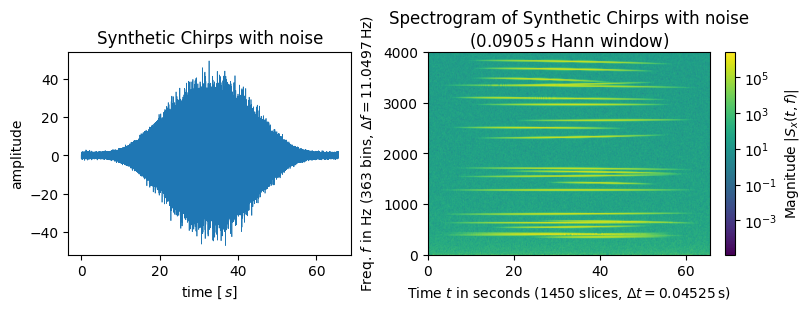

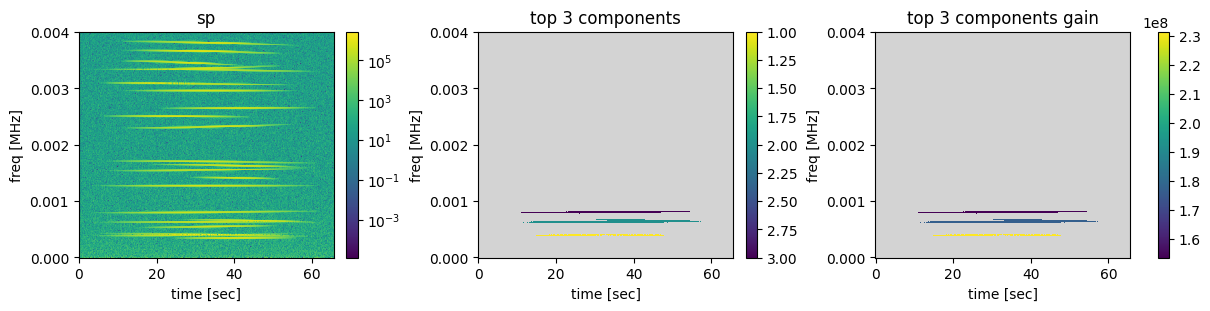

In [3]:
#@title Realistic Synthetic Data
#assert 'machinery_and_utilities' in locals(), 'must first run cell machinery_and_utilities'
example_synthetic_chirp_signal_with_noise=True

## begin make_example_synthetic_signal
doSignalPlot = True
doSignalSpectrogramPlot = True
vsz,hsz = 3,4

#don't change
nt= 524288 #8192
dt=1.0/8000.0
t=np.arange(0,nt*dt,dt)
nt=len(t)
dt=t[1]-t[0]
fs=1/dt
fN = fs/2.0
nfft=int(np.ceil(np.sqrt(nt)))
noise_mean=0 #normally 0
noise_std=1 #normally 1


chirps=[]



#rng = np.random.default_rng(seed=42)   # Same chirps every run
rng = np.random.default_rng()         # New chirps every run

n_chirps = np.random.randint(11, 25)

for i in range(n_chirps):

    # Duration: Gaussian centered at nt/2
    duration = int(rng.normal(loc=nt//1.3, scale=nt/6)) #loc = center of gaussian, scale = stdev of gaussian
    duration = np.clip(duration, nt//16, nt)  # Prevent silly values

    # Random start time
    start_idx = rng.integers(0, nt - duration + 1)
    end_idx = start_idx + duration - 1

    t0 = t[start_idx]
    t1 = t[end_idx]

    # Uniform frequencies
    # Center frequency (where the chirp lives)
    fc = rng.uniform(fN//30, fN//1.05)

    # Frequency sweep size (small on average)
    df = rng.normal(loc=0, scale=0.01*fN) #used to be 0.05fN

    f0 = fc - df/2
    f1 = fc + df/2

    # Keep inside valid range
    f0 = np.clip(f0, 0, fN)
    f1 = np.clip(f1, 0, fN)

    # Gaussian amplitude
    amp = rng.normal(loc=4.0, scale=0.5)

    chirps.append(
        Chirp(
            amp=amp,
            t0=t0,
            t1=t1,
            f0=f0,
            f1=f1
        )
    )



'''
t0= 0  # t[int(nt/5)]
t1=t[int(nt/16)+int(nt*3/4)-1]
chirps.append(Chirp(amp= 4.0, t0=t0, t1=t1, f0=0.3*fN, f1=0.55*fN)) #added to test slope method
'''


sig0 = add_funcsigs(chirps,t)

SNR = 20 #time domain SNR
sig_rms = np.sqrt(np.mean(sig0**2))
noise_std = sig_rms / SNR #since the noise rms = noise stdev since mean of the noise is 0


seedGlobal=getSavedRndGenSeed()
useSavedRndGenSeed = False
noise_generator = np.random.default_rng(seed=seedGlobal if useSavedRndGenSeed else None).normal #uniform #normal #poisson
noise_1 = make_noise(noise_mean, noise_std, t.shape, noise_generator=noise_generator )

def color_noise(noise, alpha):
    f = np.fft.rfftfreq(len(noise)); f[0] = f[1] #frequencies of each component
    return np.fft.irfft(np.fft.rfft(noise) / f**(alpha/2), n=len(noise))#real inverse fft of real fft/ freq dependent scaling factor
    #---colored noise function - 0 white, 0.5 pink, 1 brown ----

noise = color_noise(noise_1, 0.5) #around alpha of 0.3 errors in detection occur

sig = sig0 + noise #the sythetic noise signal

SNR_Colored = sig_rms/np.sqrt(np.mean(noise**2))
print(SNR, 'SNR')
print()
print( SNR_Colored, 'SNR Colored')

sigtit='Synthetic Chirps with noise'
t0=t[0]
nt=len(t)
dt=t[1]-t[0]
fs=1/dt
fN = fs/2.0
nfft=(int(np.ceil(np.sqrt(nt))) // 2) * 2
noverlap=int(nfft/2)

SFT = ShortTimeFFT.from_window(win_param='hann', fs=fs, nperseg=nfft,noverlap=noverlap)
sigstft = SFT.stft(sig)
fsigstft = SFT.f
tsigstft = SFT.t(sig.size)


print(sigstft.shape)


if doSignalPlot or doSignalSpectrogramPlot:
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    nr,nc = 1,doSignalPlot+doSignalSpectrogramPlot
    fig = plt.figure(figsize=(nc*hsz,nr*vsz),layout='constrained')
    gs = GridSpec(nr,nc, figure=fig)
    ipanel = 0

    if doSignalPlot:
        ax = fig.add_subplot(gs[0,ipanel])
        ipanel+=1
        plt.plot(t,sig,'-',linewidth=0.5)
        plt.title(sigtit,wrap=True)
        plt.xlabel(rf'time [$\,s$]')
        plt.ylabel('amplitude')

    if doSignalSpectrogramPlot:
        from matplotlib.colors import LogNorm
        ax1 = fig.add_subplot(gs[0,ipanel])
        ipanel+=1

        kwextra = {}
        vlimdict = {}
        normfunc = LogNorm
        norm = normfunc(**vlimdict)
        #cmstd = cmapIDL_Standard_Gamma_II()
        #cmap = cmstd
        cmap ='viridis'

        N=nt
        t_lo, t_hi = SFT.extent(N)[:2]  # time range of plot
        ax1.set_title(rf"Spectrogram of {sigtit}"+"\n"+rf"({SFT.m_num*SFT.T:g}$\,s$ Hann window)",wrap=True)
        ax1.set(xlabel=f"Time $t$ in seconds ({SFT.p_num(N)} slices, " +
                      rf"$\Delta t = {SFT.delta_t:g}\,$s)",
                ylabel=f"Freq. $f$ in Hz ({SFT.f_pts} bins, " +
                      rf"$\Delta f = {SFT.delta_f:g}\,$Hz)",
                xlim=(t_lo, t_hi))

        im1 = ax1.imshow(np.abs(sigstft)**2, origin='lower', aspect='auto',
                        extent=SFT.extent(N), cmap=cmap, norm=norm,**kwextra)
        plotLeg=False
        if (False):
            ##need to define "chirpfreqs" before using.  "chripfreqs" should be chirp frequencies vs t)
            ax1.plot(t, chirpfreqs, 'r--', alpha=.5, label='$f_i(t)$')
            plotLeg=True

        plt.colorbar(im1, label="Magnitude $|S_x(t, f)|$")

        if (False):
            # Shade areas where window slices stick out to the side:
            for t0_, t1_ in [(t_lo, SFT.lower_border_end[0] * SFT.T),
                            (SFT.upper_border_begin(N)[0] * SFT.T, t_hi)]:
                ax1.axvspan(t0_, t1_, color='w', linewidth=0, alpha=.2)
            for t_ in [0, N * SFT.T]:  # mark signal borders with vertical line:
                ax1.axvline(t_, color='y', linestyle='--', alpha=0.5)

        if plotLeg: ax1.legend()

## end make_example_synthetic_signal

## begin max_tree_optimimum_features

max_tree_cl = Max_Tree
sp = np.abs(sigstft)**2
fsp = fsigstft
tsp = tsigstft


spmxtr=max_tree_cl(sp,connectivity=2)
self=spmxtr

gain_choice= 'avspecdens'
#gain_choice = 'exp(entropy/area)'
#gain_choice = 'skinny'
#gain_choice = '1' #tot intesnity/area
#gain_choice = 'avspecdens_div_freq'
#gain_choice = 'avspecheight'
#gain_choice = 'neg_kldiv_wresp_uniform_intensity'
#gain_choice = 'log_energy_concentration'
#gain_choice = 'signal_energy_concentration'
gain = self.gain_predefined(gain_choice)
# gain is a matrix which represents the gain at each bin each pixel is apart of
#each pixel which is in the same maxtree bin corresponds to the same gain
mxgnndslabeltopfill,mxgntopfill = self.label_optimummaxattrnode_image_components_with_rank_and_attr(gain)

ntop=3 #used to be 10
spdict = {'sp':sp,'fsp':fsp,'tsp':tsp}
_ = show_top_components_rank_and_gain(spdict,mxgnndslabeltopfill,mxgntopfill,ntop=ntop,panelsize=(vsz,hsz),use_LogNorm_for_gain=False)


## end max_tree_optimimum_features


(363, 1450)


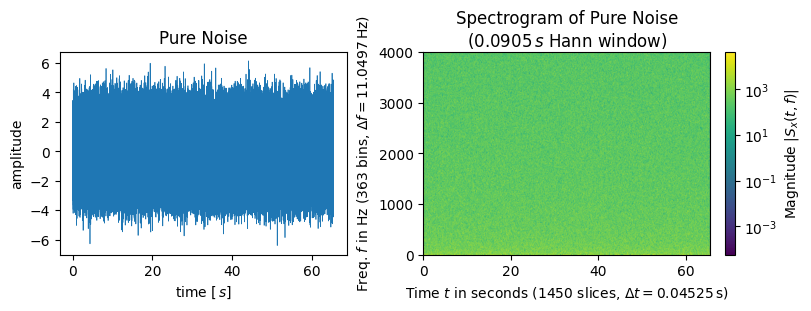

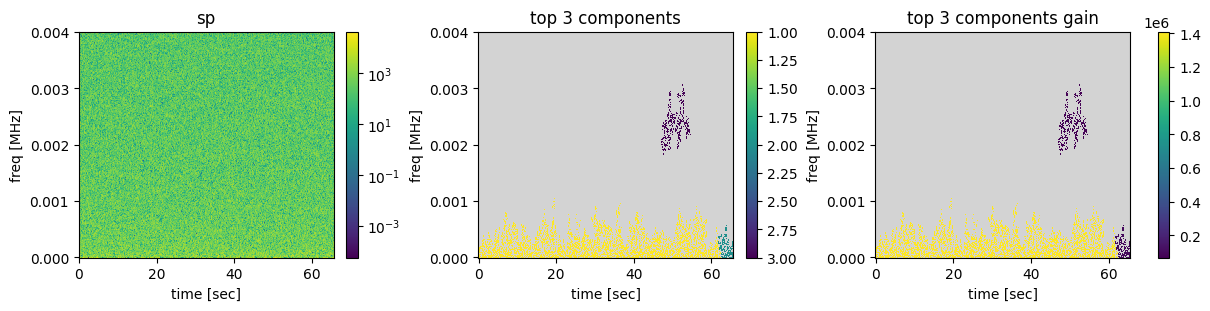

In [ ]:
#@title Pure Noise For P-Value
#assert 'machinery_and_utilities' in locals(), 'must first run cell machinery_and_utilities'
example_synthetic_chirp_signal_with_noise=True

## begin make_example_synthetic_signal
doSignalPlot = True
doSignalSpectrogramPlot = True
vsz,hsz = 3,4

#don't change
nt= 524288 # power of 2
dt=1.0/8000.0
t=np.arange(0,nt*dt,dt)
nt=len(t)
dt=t[1]-t[0]
fs=1/dt
fN = fs/2.0
nfft=int(np.ceil(np.sqrt(nt)))
noise_mean=0 #normally 0
noise_std=1 #normally 1


seedGlobal=getSavedRndGenSeed()
useSavedRndGenSeed = False
noise_generator = np.random.default_rng(seed=seedGlobal if useSavedRndGenSeed else None).normal #uniform #normal #poisson
noise_1 = make_noise(noise_mean, noise_std, t.shape, noise_generator=noise_generator )

def color_noise(noise, alpha):
    f = np.fft.rfftfreq(len(noise)); f[0] = f[1] #frequencies of each component
    return np.fft.irfft(np.fft.rfft(noise) / f**(alpha/2), n=len(noise))#real inverse fft of real fft/ freq dependent scaling factor
    #---colored noise function - 0 white, 0.5 pink, 1 brown ----

noise = color_noise(noise_1,0.3) #around alpha of 0.3 errors in detection occur

sig = noise #the sythetic noise signal


sigtit='Pure Noise'
t0=t[0]
nt=len(t)
dt=t[1]-t[0]
fs=1/dt
fN = fs/2.0
nfft=(int(np.ceil(np.sqrt(nt))) // 2) * 2
noverlap=int(nfft/2)

SFT = ShortTimeFFT.from_window(win_param='hann', fs=fs, nperseg=nfft,noverlap=noverlap)
sigstft = SFT.stft(sig)
fsigstft = SFT.f
tsigstft = SFT.t(sig.size)


print(sigstft.shape)


if doSignalPlot or doSignalSpectrogramPlot:
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    nr,nc = 1,doSignalPlot+doSignalSpectrogramPlot
    fig = plt.figure(figsize=(nc*hsz,nr*vsz),layout='constrained')
    gs = GridSpec(nr,nc, figure=fig)
    ipanel = 0

    if doSignalPlot:
        ax = fig.add_subplot(gs[0,ipanel])
        ipanel+=1
        plt.plot(t,sig,'-',linewidth=0.5)
        plt.title(sigtit,wrap=True)
        plt.xlabel(rf'time [$\,s$]')
        plt.ylabel('amplitude')

    if doSignalSpectrogramPlot:
        from matplotlib.colors import LogNorm
        ax1 = fig.add_subplot(gs[0,ipanel])
        ipanel+=1

        kwextra = {}
        vlimdict = {}
        normfunc = LogNorm
        norm = normfunc(**vlimdict)
        #cmstd = cmapIDL_Standard_Gamma_II()
        #cmap = cmstd
        cmap ='viridis'

        N=nt
        t_lo, t_hi = SFT.extent(N)[:2]  # time range of plot
        ax1.set_title(rf"Spectrogram of {sigtit}"+"\n"+rf"({SFT.m_num*SFT.T:g}$\,s$ Hann window)",wrap=True)
        ax1.set(xlabel=f"Time $t$ in seconds ({SFT.p_num(N)} slices, " +
                      rf"$\Delta t = {SFT.delta_t:g}\,$s)",
                ylabel=f"Freq. $f$ in Hz ({SFT.f_pts} bins, " +
                      rf"$\Delta f = {SFT.delta_f:g}\,$Hz)",
                xlim=(t_lo, t_hi))

        im1 = ax1.imshow(np.abs(sigstft)**2, origin='lower', aspect='auto',
                        extent=SFT.extent(N), cmap=cmap, norm=norm,**kwextra)
        plotLeg=False
        if (False):
            ##need to define "chirpfreqs" before using.  "chripfreqs" should be chirp frequencies vs t)
            ax1.plot(t, chirpfreqs, 'r--', alpha=.5, label='$f_i(t)$')
            plotLeg=True

        plt.colorbar(im1, label="Magnitude $|S_x(t, f)|$")

        if (False):
            # Shade areas where window slices stick out to the side:
            for t0_, t1_ in [(t_lo, SFT.lower_border_end[0] * SFT.T),
                            (SFT.upper_border_begin(N)[0] * SFT.T, t_hi)]:
                ax1.axvspan(t0_, t1_, color='w', linewidth=0, alpha=.2)
            for t_ in [0, N * SFT.T]:  # mark signal borders with vertical line:
                ax1.axvline(t_, color='y', linestyle='--', alpha=0.5)

        if plotLeg: ax1.legend()

## end make_example_synthetic_signal

## begin max_tree_optimimum_features

max_tree_cl = Max_Tree
sp = np.abs(sigstft)**2
fsp = fsigstft
tsp = tsigstft


spmxtr=max_tree_cl(sp,connectivity=2)
self=spmxtr

gain_choice= 'avspecdens'
#gain_choice = 'exp(entropy/area)'
#gain_choice = 'skinny'
#gain_choice = '1' #tot intesnity/area
#gain_choice = 'avspecdens_div_freq'
#gain_choice = 'avspecheight'
#gain_choice = 'neg_kldiv_wresp_uniform_intensity'
#gain_choice = 'log_energy_concentration'
#gain_choice = 'signal_energy_concentration'
gain = self.gain_predefined(gain_choice)
# gain is a matrix which represents the gain at each bin each pixel is apart of
#each pixel which is in the same maxtree bin corresponds to the same gain
mxgnndslabeltopfill,mxgntopfill = self.label_optimummaxattrnode_image_components_with_rank_and_attr(gain)

ntop=3 #used to be 10
spdict = {'sp':sp,'fsp':fsp,'tsp':tsp}
_ = show_top_components_rank_and_gain(spdict,mxgnndslabeltopfill,mxgntopfill,ntop=ntop,panelsize=(vsz,hsz),use_LogNorm_for_gain=False)


## end max_tree_optimimum_features

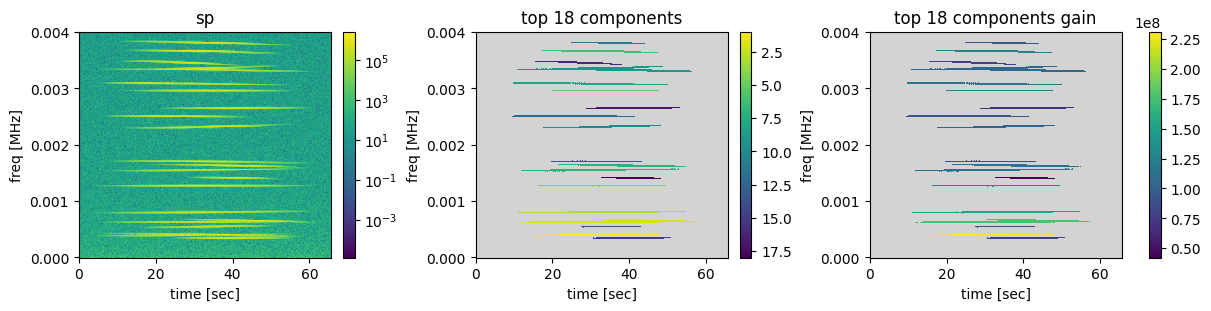

In [4]:
#@title Mode Isolation

max_tree_cl = Max_Tree
sp = np.abs(sigstft)**2
fsp = fsigstft
tsp = tsigstft
spmxtr=max_tree_cl(sp,connectivity=2)
self=spmxtr
#----Initializes the max tree stuff----



#gain_choice = 'avspecheight'
#gain_choice = 'neg_kldiv_wresp_uniform_intensity'
#gain_choice = 'log_energy_concentration'
#gain_choice='combo_specdens_signal_energy_concentration' #pretty good at telling when signal is just noise
#gain_choice = 'signal_energy_concentration' #works with slope method second best, can't tell if signal is just noise
#gain_choice = 'exp(entropy/area)'
gain_choice='avspecdens' #works with slope method extremely well, can tell if signal is just white noise
#---Imports differents gains----


gain = self.gain_predefined(gain_choice)
shape = gain.shape
mxgnndslabeltopfill,mxgntopfill = self.label_optimummaxattrnode_image_components_with_rank_and_attr(gain)



euler_nums, freq_time, tot_pix, perimeter_area_ratio, simple_freq_time = efficient_euler(mxgnndslabeltopfill)



gain_avg = avg_gain(gain, mxgnndslabeltopfill)

euler_nums = euler_nums[1:]
freq_time = freq_time[1:]
tot_pix = tot_pix[1:]
perimeter_area_ratio = perimeter_area_ratio[1:]
simple_freq_time = simple_freq_time[1:]
gain_avg = gain_avg[1:]




#---Start of Clustering Code---
X = np.column_stack((freq_time, perimeter_area_ratio, gain_avg))
X = StandardScaler().fit_transform(X) #takes the three arrays and makes them all with means of zero and stdevs of around 1, useful for data of different magnitudes


gmm = GaussianMixture(n_components=2, random_state=42, n_init=10, covariance_type='full')
labels = gmm.fit_predict(X)

counts = np.bincount(labels)
outlier_cluster = np.argmin(counts)

outliers = np.where(labels == outlier_cluster)[0]
rejects = np.where(labels != outlier_cluster)[0]

outlier_gain_avg = gain_avg[outliers]
outlier_freq_time = freq_time[outliers]
outlier_perimeter_area_ratio = perimeter_area_ratio[outliers]
outlier_tot_pix = tot_pix[outliers]
#---End of Clustering Code---

s_score = s_score_p_value(X, labels)

vsz, hsz = 3,4

if s_score < 0.8:

        freq_p, gain_p, perim_p = characteristics_p_value(outlier_freq_time, outlier_gain_avg, outlier_perimeter_area_ratio)

        freq_p_thresh = 0.001
        gain_p_thresh = 0.001
        perim_p_thresh = 0.001
        #plt.plot(freq_p, outlier_gain_avg, lw=2, color="#1f5aa6"); plt.grid(True, alpha=0.3)
        #plt.xlabel("Frequency P Value"); plt.ylabel("Avg Gain"); plt.title("P", fontweight="bold")
        #plt.tight_layout(); plt.show()


        # --- 2. Which outliers actually pass all four criteria? ---
        passes = (
            (freq_p  < freq_p_thresh)  &
            (gain_p  < gain_p_thresh)  &
            (perim_p < perim_p_thresh)
        )

        # outliers that FAIL at least one criterion get folded into "invalid" too
        failed_outliers = outliers[~passes]

        invalid = np.concatenate([rejects, failed_outliers])
        invalid = invalid + 1  # keep your existing 0-index -> label-number shift

        # --- 3. Zero out anything invalid ---
        gain[np.isin(mxgnndslabeltopfill, invalid)] = 0
        mxgnndslabeltopfill[np.isin(mxgnndslabeltopfill, invalid)] = 0

        # --- 4. Reindex remaining labels to be consecutive (0,1,2,3,...) ---
        unique_labels, mxgnndslabeltopfill = np.unique(mxgnndslabeltopfill, return_inverse=True)
        mxgnndslabeltopfill = mxgnndslabeltopfill.reshape(gain.shape)


        freqs = np.arange(shape[0])
        t = np.arange(shape[1])



        ntop = len(euler_nums) - len(invalid)



        #plot_modes_by_gain(gain, mxgnndslabeltopfill, freqs, t)

        kept = np.setdiff1d(np.arange(1, len(euler_nums)), invalid)




        #print(avg_freq_time_ratio(modes_iso_filtered[0]))
        #print(tot_pixels(modes_iso_filtered[0]))
        #print(euler_number(modes_iso_filtered[0]))
        vsz, hsz = 3,4

        spdict = {'sp':sp,'fsp':fsp,'tsp':tsp}
        _ = show_top_components_rank_and_gain(spdict,mxgnndslabeltopfill,mxgntopfill,ntop=ntop,panelsize=(vsz,hsz),use_LogNorm_for_gain=False)
        #----plot spectrogram, top components, and top components gain---

else:
    print('No Modes Selected')


In [5]:
#@title Clustering Visualization

import plotly.graph_objects as go

X = np.column_stack((freq_time, perimeter_area_ratio, gain_avg))

is_outlier = np.zeros(len(X), dtype=bool)
is_outlier[outliers] = True #outliers chosen by the gmm in Efficient Euler With Gaussian Mixture

fig = go.Figure()
for mask, color, name in [(~is_outlier, 'blue', 'Rejects'), (is_outlier, 'red', 'Outliers')]:
    fig.add_trace(go.Scatter3d(
        x=X[mask, 0],
        y=X[mask, 1],
        z=X[mask, 2],
        mode='markers',
        marker=dict(size=4, color=color, line=dict(width=0.5, color='black')),
        name=name,
    ))

fig.update_layout(
    scene=dict(
        xaxis_title='freq_time',
        yaxis_title='perimeter_area_ratio',
        zaxis_title='gain_avg',
    ),
    width=800,
    height=600,
)

fig.show() #click and drag to rotate, scroll to zoom